# Task 01


In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

## (a) Gradient and Hessian

In [2]:
x, y = sp.symbols('x y', real=True)
L = (x - 2)**2 + 2*(y + 1)**2 + x*y + sp.Rational(1, 10)*(x**4 + y**4)

grad = sp.Matrix([sp.diff(L, v) for v in (x, y)])   # gradient vector
H = sp.hessian(L, (x, y))                            # Hessian matrix

grad_s = sp.simplify(grad)
H_s = sp.simplify(H)
display(grad_s, H_s)

Matrix([
[2*x**3/5 + 2*x + y - 4],
[x + 2*y**3/5 + 4*y + 4]])

Matrix([
[6*x**2/5 + 2,            1],
[           1, 6*y**2/5 + 4]])

## (b) Numerical optimisation

In [3]:
# turn the SymPy expressions into fast NumPy functions
L_f    = sp.lambdify((x, y), L, 'numpy')
grad_f = sp.lambdify((x, y), grad, 'numpy')
H_f    = sp.lambdify((x, y), H, 'numpy')

fun  = lambda p: L_f(*p)
jac  = lambda p: np.array(grad_f(*p), dtype=float).ravel()   # gradient
hess = lambda p: np.array(H_f(*p), dtype=float)              # Hessian

x0 = np.array([0.0, 0.0])
path = [x0.copy()]                       # store the iteration path for part (d)

# Newton-Raphson applied to the gradient: p_{k+1} = p_k - H^{-1} grad L
res = optimize.minimize(fun, x0, jac=jac, hess=hess, method='Newton-CG',
                        options={'xtol': 1e-10},
                        callback=lambda xk: path.append(xk.copy()))
path = np.array(path)

x_star = res.x
print("Method: Newton-Raphson method (using the exact gradient and Hessian)")
print("Stopping criterion: step size < 1e-10")
print("Converged:", res.success, "|", res.message)
print("Iterations:", res.nit)
print("Stationary point:", x_star)
print("Gradient norm:", np.linalg.norm(jac(x_star)))
print("Loss value:", res.fun)

Method: Newton-Raphson method (using the exact gradient and Hessian)
Stopping criterion: step size < 1e-10
Converged: True | Optimization terminated successfully.
Iterations: 7
Stationary point: [ 1.67539691 -1.2318992 ]
Gradient norm: 3.3793432308142483e-12
Loss value: -0.8327953588422357


## (c) Classification of the stationary point

In [4]:
H_star = np.array(H_f(*x_star), dtype=float)   # Hessian evaluated at the point
eigvals = np.linalg.eigvalsh(H_star)           # eigvalsh: for symmetric matrices
print("Hessian at stationary point:\n", H_star)
print("Eigenvalues:", eigvals)

if np.all(eigvals > 0):
    print("Both eigenvalues positive -> local minimum")
elif np.all(eigvals < 0):
    print("Both eigenvalues negative -> local maximum")
else:
    print("Mixed signs -> saddle point")

Hessian at stationary point:
 [[5.36834578 1.        ]
 [1.         5.82109078]]
Eigenvalues: [4.56941613 6.62002044]
Both eigenvalues positive -> local minimum


### Interpretation and Global Optimality

* **What the eigenvalues mean:** Evaluated at the stationary point $(x^*, y^*) \approx (1.6754, -1.2319)$, the Hessian is
  $$H(x^*, y^*) \approx \begin{bmatrix} 5.368 & 1 \\ 1 & 5.821 \end{bmatrix}$$
  Each eigenvalue of this matrix represents the curvature of $L$ along one principal (eigenvector) direction. Both eigenvalues ($\approx 4.57$ and $\approx 6.62$) are strictly positive, so $L$ curves upward in every direction around $(x^*, y^*)$, which confirms a local minimum.

* **Why the point is stationary:** A stationary point requires $\nabla L(x^*, y^*) = \mathbf{0}$. After Newton-Raphson optimisation, the gradient norm is $\approx 3.4 \times 10^{-12}$, so the gradient is effectively zero at this point.

* **Why it is the global minimum:** From part (a), the Hessian is
  $$H(x, y) = \begin{bmatrix} 1.2x^2 + 2 & 1 \\ 1 & 1.2y^2 + 4 \end{bmatrix}$$
  The top-left entry satisfies $1.2x^2 + 2 \ge 2 > 0$ for all $(x, y) \in \mathbb{R}^2$, and the determinant is
  $$\det H(x, y) = (1.2x^2 + 2)(1.2y^2 + 4) - 1 \ge (2)(4) - 1 = 7 > 0$$ Since the determinant equals the product of the two eigenvalues, $\det H > 0$ means both eigenvalues have the same sign; and since the top-left entry is positive, they cannot both be negative. Hence both eigenvalues of $H(x, y)$ are positive for every $(x, y)$, so $H$ is positive definite everywhere on $\mathbb{R}^2$. Therefore $L$ is strictly convex on $\mathbb{R}^2$. A strictly convex function has at most one stationary point, and any stationary point it has is a global minimum. Hence $(x^*, y^*)$ is the unique global minimiser of $L$, with $L(x^*, y^*) \approx -0.8328$.

## (d) Contour plot

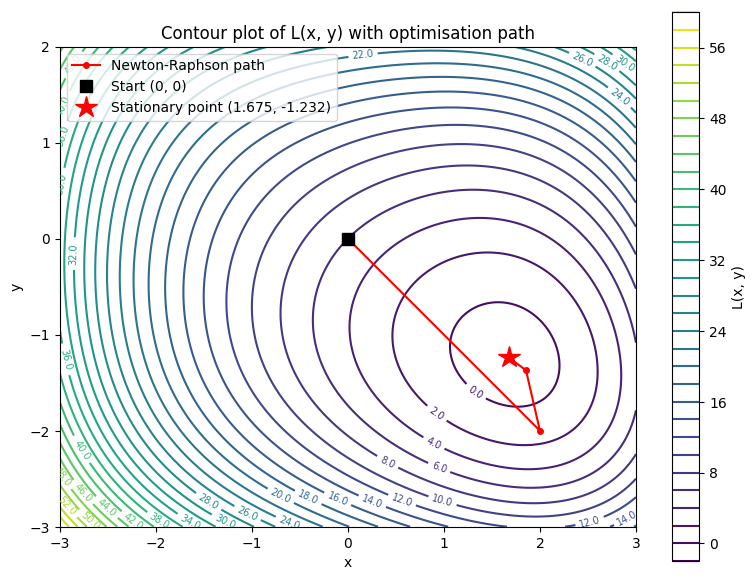

In [5]:
xs = np.linspace(-3, 3, 400)          # x range
ys = np.linspace(-3, 2, 400)          # y range
X, Y = np.meshgrid(xs, ys)            # 2D grid of (x, y) points
Z = L_f(X, Y)                         # loss at every grid point

fig, ax = plt.subplots(figsize=(8, 6))
cs = ax.contour(X, Y, Z, levels=30, cmap='viridis')
ax.clabel(cs, inline=True, fontsize=7, fmt='%.1f')
fig.colorbar(cs, ax=ax, label='L(x, y)')

ax.plot(path[:, 0], path[:, 1], 'o-', color='red', markersize=4, label='Newton-Raphson path')
ax.plot(*x0, 'ks', markersize=9, label='Start (0, 0)')
ax.plot(*x_star, 'r*', markersize=16,
        label=f'Stationary point ({x_star[0]:.3f}, {x_star[1]:.3f})')

ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Contour plot of L(x, y) with optimisation path')
ax.legend(loc='upper left'); ax.set_aspect('equal')
plt.tight_layout(); plt.show()